# Heart Disease Prediction — End-to-End MLOps (single notebook)
**Course:** MLOps (AIMLCZG523) · Assignment 01

This one notebook contains the whole project. Run it top to bottom from an empty folder and it will:
1. create every project file (source, tests, CI workflow, Dockerfile, Kubernetes, monitoring configs),
2. download the data, run EDA, train and compare models with MLflow,
3. run the tests and the API, and
4. show the exact Docker / GitHub / Kubernetes commands (Part 6).

Set up a venv first, then `pip install jupyter` and open this notebook from that venv. Educational model only, not for clinical use.

## Part 0 — Project skeleton and dependencies

In [1]:
import os

for d in ["src","tests","scripts","monitoring","k8s",".github/workflows","data/raw","data/processed","model","artifacts/eda","screenshots"]:
    os.makedirs(d, exist_ok=True)
print("folders ready:", os.getcwd())

folders ready: C:\Users\devis\OneDrive\Desktop\BitsPilani\3rdSemester\MLOPs\MLOPs_Assignment1


In [2]:
%%writefile requirements.txt
numpy>=1.24
pandas>=2.0
scikit-learn>=1.3
joblib>=1.3
matplotlib>=3.7
mlflow>=2.10
fastapi>=0.110
uvicorn[standard]>=0.27
pydantic>=2
prometheus-client>=0.20
pytest>=8
httpx>=0.27
ruff>=0.4
tabulate>=0.9


Writing requirements.txt


In [3]:
%%writefile requirements-api.txt
numpy>=1.24
pandas>=2.0
scikit-learn>=1.3
joblib>=1.3
fastapi>=0.110
uvicorn[standard]>=0.27
pydantic>=2
prometheus-client>=0.20


Writing requirements-api.txt


In [4]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


## Part 1 — Data and feature code

In [5]:
# empty package marker file
open('src/__init__.py', 'w').close()

In [6]:
%%writefile src/data.py
"""Data loading and cleaning for the Heart Disease (Cleveland) dataset."""
from pathlib import Path

import pandas as pd

COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
           "exang", "oldpeak", "slope", "ca", "thal", "target"]
FEATURES = COLUMNS[:-1]
CATEGORICAL = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]
TARGET = "target"


def load_raw(path) -> pd.DataFrame:
    """Read the headerless UCI file; '?' marks missing values."""
    return pd.read_csv(Path(path), header=None, names=COLUMNS, na_values="?")


def binarize_target(series: pd.Series) -> pd.Series:
    """UCI target 0 = healthy, 1-4 = disease present -> 0/1."""
    return (series > 0).astype(int)


def clean(df: pd.DataFrame) -> pd.DataFrame:
    """Coerce to numeric, drop rows without target, binarize target, drop duplicates.

    Missing predictor values are kept: they are imputed inside the model pipeline
    so no information leaks from test folds.
    """
    out = df.copy()
    for col in COLUMNS:
        out[col] = pd.to_numeric(out[col], errors="coerce")
    out = out.dropna(subset=[TARGET])
    out[TARGET] = binarize_target(out[TARGET])
    return out.drop_duplicates().reset_index(drop=True)


Writing src/data.py


In [7]:
%%writefile src/features.py
"""Preprocessing pipeline: impute + scale numerics, impute + one-hot categoricals."""
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.data import CATEGORICAL, NUMERIC


def build_preprocessor() -> ColumnTransformer:
    numeric = Pipeline([("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler())])
    categorical = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                            ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("numeric", numeric, NUMERIC),
                              ("categorical", categorical, CATEGORICAL)])


Writing src/features.py


In [8]:
%%writefile scripts/download_data.py
"""Download the UCI Heart Disease dataset (Cleveland subset) and write raw + cleaned CSVs."""
import io
import sys
import urllib.request
import zipfile
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))
from src.data import clean, load_raw

URL = "https://archive.ics.uci.edu/static/public/45/heart+disease.zip"
RAW_DIR = ROOT / "data" / "raw"
OUT = ROOT / "data" / "processed" / "heart_clean.csv"


def main() -> None:
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    target = RAW_DIR / "processed.cleveland.data"
    if not target.exists():
        print("Downloading", URL)
        with urllib.request.urlopen(URL, timeout=60) as r:
            data = r.read()
        with zipfile.ZipFile(io.BytesIO(data)) as zf:
            zf.extract("processed.cleveland.data", RAW_DIR)
    df = clean(load_raw(target))
    OUT.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(OUT, index=False)
    print(f"Wrote {OUT} shape={df.shape}")


if __name__ == "__main__":
    main()


Writing scripts/download_data.py


In [9]:
!python scripts/download_data.py

Wrote C:\Users\devis\OneDrive\Desktop\BitsPilani\3rdSemester\MLOPs\MLOPs_Assignment1\data\processed\heart_clean.csv shape=(303, 14)


## Part 2 — Exploratory Data Analysis

In [10]:
import os
import sys

sys.path.insert(0, os.getcwd())
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from src.data import clean, load_raw

raw = load_raw('data/raw/processed.cleveland.data')
print('raw shape', raw.shape)
print('missing values:'); print(raw.isna().sum()[lambda s: s>0])
df = clean(raw)
print('clean shape', df.shape)
df['target'].value_counts()

raw shape (303, 14)
missing values:
ca      4
thal    2
dtype: int64
clean shape (303, 14)


target
0    164
1    139
Name: count, dtype: int64

In [11]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


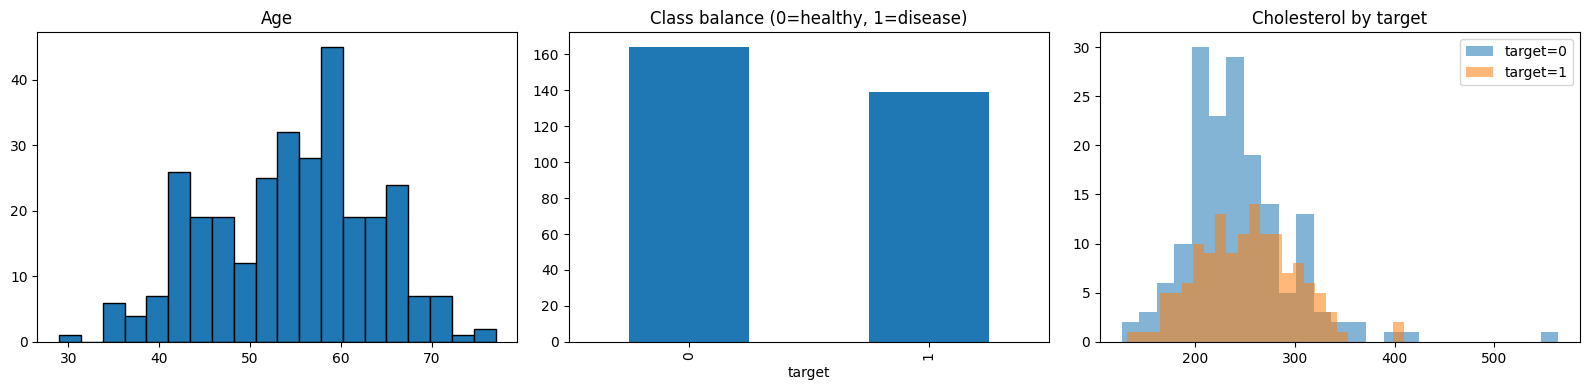

In [12]:
EDA = Path('artifacts/eda')
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(df['age'], bins=20, edgecolor='k'); ax[0].set_title('Age')
df['target'].value_counts().sort_index().plot.bar(ax=ax[1]); ax[1].set_title('Class balance (0=healthy, 1=disease)')
for t, g in df.groupby('target'): ax[2].hist(g['chol'], bins=25, alpha=.55, label=f'target={t}')
ax[2].set_title('Cholesterol by target'); ax[2].legend()
fig.tight_layout(); fig.savefig(EDA/'distributions.png', dpi=150); plt.show()

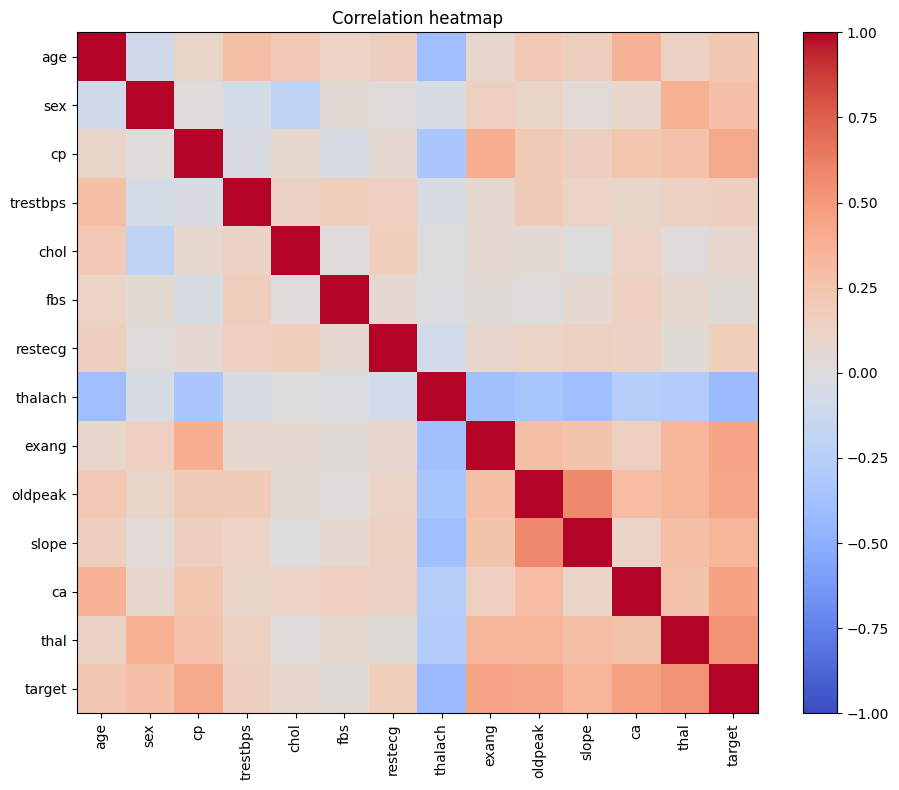

In [13]:
fig, ax = plt.subplots(figsize=(10, 8)); corr = df.corr()
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90); ax.set_yticks(range(len(corr)), corr.columns)
fig.colorbar(im); ax.set_title('Correlation heatmap'); fig.tight_layout()
fig.savefig(EDA/'correlation.png', dpi=150); plt.show()

**Write your own observations here** (class balance, which features separate the classes, missing `ca`/`thal`, outliers in `chol`). The report needs your own words.

## Part 3 — Training with cross-validation and MLflow
Every candidate (3 Logistic Regression + 8 Random Forest settings) is logged as its own MLflow run; the best by CV ROC-AUC is evaluated on the hold-out set, logged as a final run, and saved to `model/heart_disease_pipeline.joblib`.

In [14]:
%%writefile src/train.py
"""Train, cross-validate and tune models; log EVERY run to MLflow; save best pipeline."""
import argparse
import json
import os
import sys
from pathlib import Path

import joblib
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    ParameterGrid,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))
from src.data import FEATURES, TARGET
from src.features import build_preprocessor

SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "roc_auc": "roc_auc"}
SEED = 42


def candidates():
    """Yield (run_name, params, pipeline) for every model configuration tried."""
    for C in [0.1, 1.0, 10.0]:
        yield (f"logreg_C{C}", {"model": "LogisticRegression", "C": C},
               Pipeline([("pre", build_preprocessor()),
                         ("clf", LogisticRegression(C=C, max_iter=2000, class_weight="balanced",
                                                    random_state=SEED))]))
    grid = {"n_estimators": [200, 400], "max_depth": [None, 8], "min_samples_leaf": [1, 2]}
    for p in ParameterGrid(grid):
        yield (f"rf_n{p['n_estimators']}_d{p['max_depth']}_l{p['min_samples_leaf']}",
               {"model": "RandomForest", **p},
               Pipeline([("pre", build_preprocessor()),
                         ("clf", RandomForestClassifier(class_weight="balanced", random_state=SEED,
                                                        n_jobs=-1, **p))]))


def main(data_path: Path, out_dir: Path, model_dir: Path, mlflow_dir: Path) -> dict:
    df = pd.read_csv(data_path)
    X, y = df[FEATURES], df[TARGET].astype(int)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

    out_dir.mkdir(parents=True, exist_ok=True)
    model_dir.mkdir(parents=True, exist_ok=True)
    mlflow_dir.mkdir(parents=True, exist_ok=True)
    exp = "heart-disease-classification"
    server_uri = os.environ.get("MLFLOW_TRACKING_URI")
    if server_uri:  # remote MLflow server (e.g. the docker-compose "mlflow" service)
        mlflow.set_tracking_uri(server_uri)
    else:  # local SQLite store
        mlflow.set_tracking_uri(f"sqlite:///{(mlflow_dir / 'mlflow.db').resolve().as_posix()}")
        if mlflow.get_experiment_by_name(exp) is None:
            mlflow.create_experiment(exp, artifact_location=(mlflow_dir / "artifacts").resolve().as_uri())
    mlflow.set_experiment(exp)

    rows, best = [], None
    for name, params, pipe in candidates():
        with mlflow.start_run(run_name=name):
            mlflow.log_params({**params, "cv_folds": 5, "seed": SEED})
            s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=1)
            metrics = {}
            for m in SCORING:
                metrics[f"cv_{m}_mean"] = float(np.mean(s[f"test_{m}"]))
                metrics[f"cv_{m}_std"] = float(np.std(s[f"test_{m}"]))
            mlflow.log_metrics(metrics)
            oof = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
            fig, ax = plt.subplots(1, 2, figsize=(10, 4))
            ConfusionMatrixDisplay.from_predictions(y_train, (oof >= 0.5).astype(int), ax=ax[0], cmap="Blues")
            RocCurveDisplay.from_predictions(y_train, oof, ax=ax[1])
            ax[0].set_title(f"{name}: CV confusion matrix")
            ax[1].set_title("CV ROC curve")
            fig.tight_layout()
            mlflow.log_figure(fig, "cv_evaluation.png")
            plt.close(fig)
            rows.append({"run": name, **params, **metrics})
            if best is None or metrics["cv_roc_auc_mean"] > best[0]:
                best = (metrics["cv_roc_auc_mean"], name, params, pipe)

    cv_df = pd.DataFrame(rows).sort_values("cv_roc_auc_mean", ascending=False)
    cv_df.to_csv(out_dir / "cv_results.csv", index=False)

    _, best_name, best_params, best_pipe = best
    best_pipe.fit(X_train, y_train)
    pred = best_pipe.predict(X_test)
    prob = best_pipe.predict_proba(X_test)[:, 1]
    final = {
        "selected_run": best_name, "selected_params": best_params,
        "cv_roc_auc": best[0],
        "test_accuracy": float(accuracy_score(y_test, pred)),
        "test_precision": float(precision_score(y_test, pred, zero_division=0)),
        "test_recall": float(recall_score(y_test, pred, zero_division=0)),
        "test_roc_auc": float(roc_auc_score(y_test, prob)),
        "n_train": len(X_train), "n_test": len(X_test),
    }
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax[0], cmap="Blues")
    RocCurveDisplay.from_predictions(y_test, prob, ax=ax[1])
    fig.tight_layout()
    fig.savefig(out_dir / "holdout_evaluation.png", dpi=150)
    plt.close(fig)
    (out_dir / "final_metrics.json").write_text(json.dumps(final, indent=2))

    with mlflow.start_run(run_name=f"FINAL_{best_name}"):
        mlflow.log_params({**best_params, "stage": "final_holdout"})
        mlflow.log_metrics({k: v for k, v in final.items() if k.startswith(("test_", "cv_"))})
        for f in ["cv_results.csv", "holdout_evaluation.png", "final_metrics.json"]:
            mlflow.log_artifact(str(out_dir / f))
        mlflow.sklearn.log_model(best_pipe, name="model", input_example=X_train.head(3),
                                 serialization_format="cloudpickle")

    joblib.dump(best_pipe, model_dir / "heart_disease_pipeline.joblib")
    print(json.dumps(final, indent=2))
    return final


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", default=str(ROOT / "data/processed/heart_clean.csv"))
    ap.add_argument("--out", default=str(ROOT / "artifacts"))
    ap.add_argument("--model-dir", default=str(ROOT / "model"))
    ap.add_argument("--mlflow-dir", default=str(ROOT / "mlflow_data"))
    a = ap.parse_args()
    main(Path(a.data), Path(a.out), Path(a.model_dir), Path(a.mlflow_dir))


Writing src/train.py


Helper that prints an MLflow run table (used by the CI job summary):

In [15]:
%%writefile scripts/mlflow_summary.py
"""Print a markdown table of all MLflow runs (used for the GitHub Actions job summary)."""
import sys
from pathlib import Path

import mlflow

store = Path(sys.argv[1] if len(sys.argv) > 1 else "mlflow_data")
mlflow.set_tracking_uri(f"sqlite:///{(store / 'mlflow.db').resolve().as_posix()}")
runs = mlflow.search_runs(experiment_names=["heart-disease-classification"],
                          order_by=["metrics.cv_roc_auc_mean DESC"])
cols = ["tags.mlflow.runName", "metrics.cv_accuracy_mean", "metrics.cv_precision_mean",
        "metrics.cv_recall_mean", "metrics.cv_roc_auc_mean"]
t = runs[cols].rename(columns=lambda c: c.split(".")[-1]).round(3)
print(f"### MLflow experiment: {len(runs)} runs\n")
print(t.to_markdown(index=False))


Writing scripts/mlflow_summary.py


In [16]:
from importlib import reload

from src import train

reload(train)
final = train.main(Path('data/processed/heart_clean.csv'), Path('artifacts'), Path('model'), Path('mlflow_data'))
final

2026/10/20 20:51:18 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/20 20:51:18 INFO mlflow.store.db.utils: Updating database tables
2026-10-20 20:51:18 INFO  [alembic.runtime.migration] Context impl SQLiteImpl.
2026-10-20 20:51:18 INFO  [alembic.runtime.migration] Will assume non-transactional DDL.
2026-10-20 20:51:19 INFO  [alembic.runtime.migration] Running upgrade  -> 451aebb31d03, add metric step
2026-10-20 20:51:19 INFO  [alembic.runtime.migration] Running upgrade 451aebb31d03 -> 90e64c465722, migrate user column to tags
2026-10-20 20:51:19 INFO  [alembic.runtime.migration] Running upgrade 90e64c465722 -> 181f10493468, allow nulls for metric values
2026-10-20 20:51:19 INFO  [alembic.runtime.migration] Running upgrade 181f10493468 -> df50e92ffc5e, Add Experiment Tags Table
2026-10-20 20:51:19 INFO  [alembic.runtime.migration] Running upgrade df50e92ffc5e -> 7ac759974ad8, Update run tags with larger limit
2026-10-20 20:51:19 INFO  [alembic.runtime.mig

{
  "selected_run": "logreg_C0.1",
  "selected_params": {
    "model": "LogisticRegression",
    "C": 0.1
  },
  "cv_roc_auc": 0.9027904462687071,
  "test_accuracy": 0.8852459016393442,
  "test_precision": 0.8387096774193549,
  "test_recall": 0.9285714285714286,
  "test_roc_auc": 0.9653679653679654,
  "n_train": 242,
  "n_test": 61
}


{'selected_run': 'logreg_C0.1',
 'selected_params': {'model': 'LogisticRegression', 'C': 0.1},
 'cv_roc_auc': 0.9027904462687071,
 'test_accuracy': 0.8852459016393442,
 'test_precision': 0.8387096774193549,
 'test_recall': 0.9285714285714286,
 'test_roc_auc': 0.9653679653679654,
 'n_train': 242,
 'n_test': 61}

In [17]:
pd.read_csv('artifacts/cv_results.csv').round(3)

,run,model,C,cv_accuracy_mean,cv_accuracy_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_roc_auc_mean,cv_roc_auc_std,max_depth,min_samples_leaf,n_estimators
0,logreg_C0.1,LogisticRegression,0.1,0.830,0.017,0.823,0.043,0.810,0.068,0.903,0.017,NaN,NaN,NaN
1,logreg_C1.0,LogisticRegression,1.0,0.855,0.024,0.873,0.062,0.810,0.062,0.902,0.015,NaN,NaN,NaN
2,rf_n200_d8_l2,RandomForest,NaN,0.801,0.023,0.786,0.052,0.792,0.095,0.901,0.031,8.0,2.0,200.0
3,logreg_C10.0,LogisticRegression,10.0,0.843,0.021,0.852,0.052,0.802,0.024,0.901,0.013,NaN,NaN,NaN
4,rf_n200_dNone_l2,RandomForest,NaN,0.801,0.023,0.786,0.052,0.792,0.095,0.900,0.029,NaN,2.0,200.0
5,rf_n200_d8_l1,RandomForest,NaN,0.810,0.025,0.812,0.029,0.765,0.085,0.898,0.028,8.0,1.0,200.0
6,rf_n400_dNone_l1,RandomForest,NaN,0.810,0.016,0.807,0.029,0.774,0.078,0.898,0.035,NaN,1.0,400.0
7,rf_n400_dNone_l2,RandomForest,NaN,0.806,0.030,0.797,0.050,0.783,0.094,0.897,0.031,NaN,2.0,400.0
8,rf_n400_d8_l2,RandomForest,NaN,0.810,0.029,0.804,0.048,0.783,0.094,0.897,0.031,8.0,2.0,400.0
9,rf_n400_d8_l1,RandomForest,NaN,0.814,0.023,0.809,0.029,0.783,0.089,0.897,0.031,8.0,1.0,400.0


### MLflow: see the runs in your browser
Run the next cell. It starts the MLflow UI for you (it needs the training cell above to have finished, because that creates `mlflow_data/mlflow.db`) and prints a link. **Give it 10-20 seconds the first time.** It uses port 5001 (or the next free port) because port 5000 is often taken by other programs.

If you prefer a terminal, run this **from the project folder** (same folder as `mlflow_data/`; from anywhere else it opens an empty store):
```
mlflow ui --backend-store-uri sqlite:///mlflow_data/mlflow.db --port 5001
```
- **Docker:** `docker compose up -d mlflow`, wait about 20 seconds, then open http://localhost:5001. Train into it with `docker compose --profile train run --rm train`.
- **GitHub Actions:** the *MLflow run summary* step prints the run table on the workflow summary page, and `mlflow_data/` is uploaded as an artifact (download it, then use the local command).

In [18]:
import socket
import subprocess
import sys
import time
import urllib.request
from pathlib import Path

from IPython.display import HTML, display

store = Path("mlflow_data/mlflow.db").resolve()
assert store.exists(), "Run the training cell first: it creates mlflow_data/mlflow.db"


def free_port(start=5001):
    for port in range(start, start + 20):
        with socket.socket() as s:
            if s.connect_ex(("127.0.0.1", port)) != 0:
                return port
    raise RuntimeError("no free port found")


PORT = free_port()
mlflow_ui = subprocess.Popen([sys.executable, "-m", "mlflow", "ui",
                              "--backend-store-uri", f"sqlite:///{store.as_posix()}",
                              "--host", "127.0.0.1", "--port", str(PORT)])
for _ in range(120):
    try:
        urllib.request.urlopen(f"http://127.0.0.1:{PORT}/health", timeout=2)
        break
    except Exception:
        time.sleep(1)
else:
    raise RuntimeError("MLflow UI did not start within 2 minutes; check the messages above")
display(HTML(f'MLflow UI is running: <a href="http://127.0.0.1:{PORT}" target="_blank">http://127.0.0.1:{PORT}</a>'))

**Option: show the MLflow page inside this notebook** (works in Jupyter on your own computer; if it shows blank, open the link above in your browser instead):

In [19]:
from IPython.display import IFrame

IFrame(f"http://127.0.0.1:{PORT}", width="100%", height=700)

**Option: show all MLflow runs inside the notebook, no server needed** (always works, good for a report screenshot):

In [20]:
from pathlib import Path

import mlflow

mlflow.set_tracking_uri(f"sqlite:///{Path('mlflow_data/mlflow.db').resolve().as_posix()}")
runs = mlflow.search_runs(experiment_names=["heart-disease-classification"],
                          order_by=["metrics.cv_roc_auc_mean DESC"])
runs[["tags.mlflow.runName", "metrics.cv_accuracy_mean", "metrics.cv_precision_mean",
      "metrics.cv_recall_mean", "metrics.cv_roc_auc_mean"]].round(3)

,tags.mlflow.runName,metrics.cv_accuracy_mean,metrics.cv_precision_mean,metrics.cv_recall_mean,metrics.cv_roc_auc_mean
0,logreg_C0.1,0.830,0.823,0.810,0.903
1,logreg_C1.0,0.855,0.873,0.810,0.902
2,rf_n200_d8_l2,0.801,0.786,0.792,0.901
3,logreg_C10.0,0.843,0.852,0.802,0.901
4,rf_n200_dNone_l2,0.801,0.786,0.792,0.900
5,rf_n200_d8_l1,0.810,0.812,0.765,0.898
6,rf_n400_dNone_l1,0.810,0.807,0.774,0.898
7,rf_n400_dNone_l2,0.806,0.797,0.783,0.897
8,rf_n400_d8_l2,0.810,0.804,0.783,0.897
9,rf_n400_d8_l1,0.814,0.809,0.783,0.897


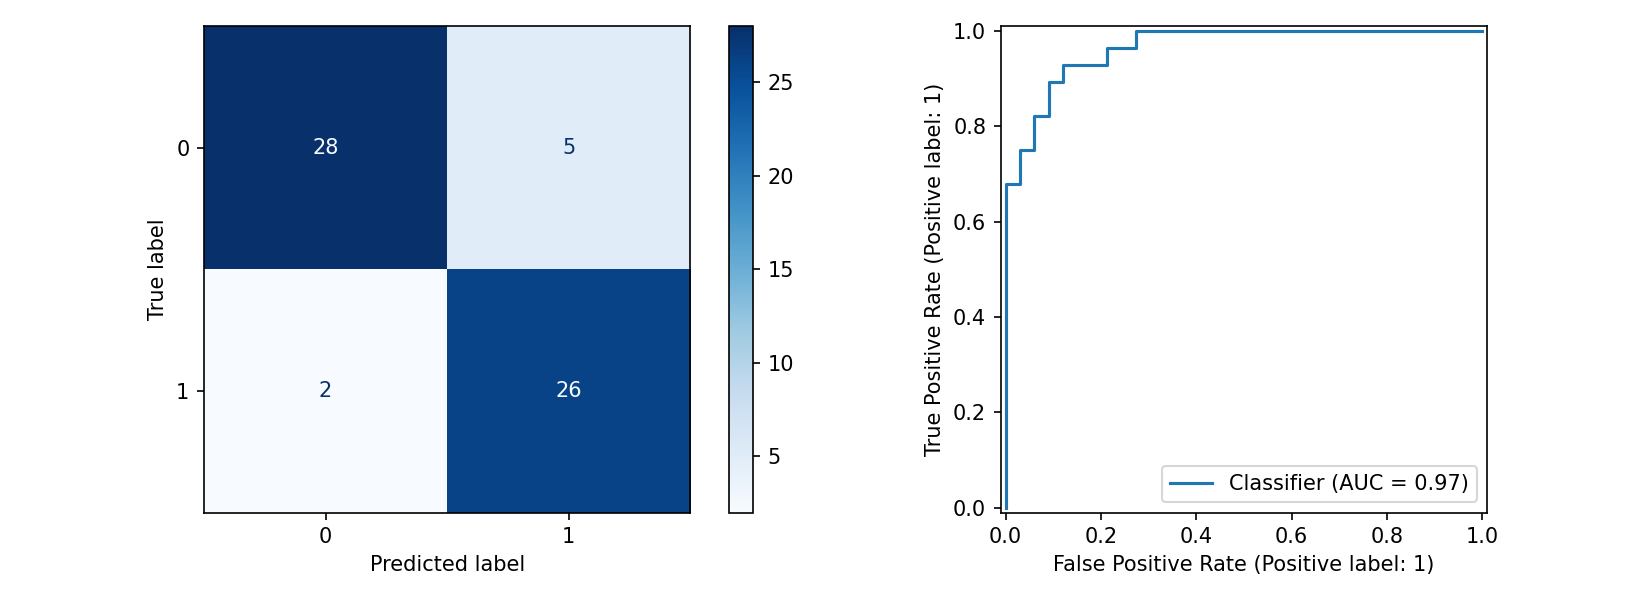

In [21]:
from IPython.display import Image

Image("artifacts/holdout_evaluation.png")   # confusion matrix and ROC curve of the final model

In [22]:
# Run this when you are done, to stop the MLflow UI
mlflow_ui.terminate()

View experiments in the MLflow UI with the cells under *MLflow: see the runs in your browser* below. Take a screenshot of the run list and the final run for the report.

## Part 4 — Serving API (FastAPI) with logging and Prometheus metrics

In [23]:
%%writefile app.py
"""FastAPI model server with request logging and Prometheus metrics."""
import logging
import os
import time
import uuid
from pathlib import Path

import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException, Request, Response
from prometheus_client import CONTENT_TYPE_LATEST, Counter, Histogram, generate_latest
from pydantic import BaseModel, Field

logging.basicConfig(level=os.getenv("LOG_LEVEL", "INFO"),
                    format="%(asctime)s %(levelname)s %(message)s")
logger = logging.getLogger("heart-api")

MODEL_PATH = Path(os.getenv("MODEL_PATH", Path(__file__).parent / "model" / "heart_disease_pipeline.joblib"))
FEATURES = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
            "exang", "oldpeak", "slope", "ca", "thal"]
model = joblib.load(MODEL_PATH)

REQS = Counter("api_requests_total", "HTTP requests", ["method", "path", "status"])
LATENCY = Histogram("api_request_latency_seconds", "Request latency", ["path"])
PREDS = Counter("api_predictions_total", "Predictions by class", ["label"])

app = FastAPI(title="Heart Disease Prediction API", version="2.0.0")


class Features(BaseModel):
    age: float = Field(..., ge=1, le=120)
    sex: int = Field(..., ge=0, le=1)
    cp: int = Field(..., ge=1, le=4, description="chest pain type")
    trestbps: float = Field(..., ge=50, le=260)
    chol: float = Field(..., ge=50, le=700)
    fbs: int = Field(..., ge=0, le=1)
    restecg: int = Field(..., ge=0, le=2)
    thalach: float = Field(..., ge=40, le=250)
    exang: int = Field(..., ge=0, le=1)
    oldpeak: float = Field(..., ge=0, le=10)
    slope: int = Field(..., ge=1, le=3)
    ca: float = Field(..., ge=0, le=4)
    thal: float = Field(..., ge=3, le=7)


class PredictRequest(BaseModel):
    features: Features


@app.middleware("http")
async def log_requests(request: Request, call_next):
    rid = uuid.uuid4().hex[:8]
    start = time.perf_counter()
    status = 500
    try:
        response = await call_next(request)
        status = response.status_code
        return response
    finally:
        dur = time.perf_counter() - start
        path = request.url.path
        if path != "/metrics":
            REQS.labels(request.method, path, str(status)).inc()
            LATENCY.labels(path).observe(dur)
        logger.info("req_id=%s method=%s path=%s status=%s latency_ms=%.1f",
                    rid, request.method, path, status, dur * 1000)


@app.get("/health")
def health():
    return {"status": "ok", "model_loaded": model is not None}


@app.get("/metrics")
def metrics():
    return Response(generate_latest(), media_type=CONTENT_TYPE_LATEST)


@app.post("/predict")
def predict(req: PredictRequest):
    try:
        row = pd.DataFrame([req.features.model_dump()], columns=FEATURES)
        pred = int(model.predict(row)[0])
        proba = model.predict_proba(row)[0]
    except Exception:
        logger.exception("Prediction failed")
        raise HTTPException(status_code=400, detail="Unable to process feature values")
    label = "disease_present" if pred == 1 else "no_disease"
    PREDS.labels(label).inc()
    logger.info("prediction=%s disease_probability=%.3f", label, proba[1])
    return {"prediction": pred, "label": label,
            "confidence": float(max(proba)), "disease_probability": float(proba[1])}


Writing app.py


## Part 5 — Tests, lint and CI

In [24]:
%%writefile tests/conftest.py
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import pytest

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from src.data import COLUMNS


@pytest.fixture(scope="session")
def synthetic_raw():
    """Small synthetic frame shaped like the raw UCI file (incl. NaNs and 0-4 target)."""
    rng = np.random.default_rng(0)
    n = 120
    df = pd.DataFrame({
        "age": rng.integers(30, 77, n), "sex": rng.integers(0, 2, n),
        "cp": rng.integers(1, 5, n), "trestbps": rng.integers(95, 200, n),
        "chol": rng.integers(125, 560, n), "fbs": rng.integers(0, 2, n),
        "restecg": rng.integers(0, 3, n), "thalach": rng.integers(71, 202, n),
        "exang": rng.integers(0, 2, n), "oldpeak": rng.uniform(0, 6, n).round(1),
        "slope": rng.integers(1, 4, n), "ca": rng.integers(0, 4, n).astype(float),
        "thal": rng.choice([3.0, 6.0, 7.0], n), "target": rng.integers(0, 5, n),
    })[COLUMNS]
    df.loc[3, "ca"] = np.nan
    df.loc[7, "thal"] = np.nan
    return df


@pytest.fixture(scope="session")
def synthetic_clean(synthetic_raw):
    from src.data import clean
    return clean(synthetic_raw)


Writing tests/conftest.py


In [25]:
%%writefile tests/test_data.py
import pandas as pd

from src.data import CATEGORICAL, COLUMNS, FEATURES, NUMERIC, binarize_target, clean, load_raw


def test_schema_constants():
    assert len(FEATURES) == 13 and len(COLUMNS) == 14
    assert set(CATEGORICAL) | set(NUMERIC) == set(FEATURES)
    assert not set(CATEGORICAL) & set(NUMERIC)


def test_binarize_target():
    out = binarize_target(pd.Series([0, 1, 2, 3, 4]))
    assert out.tolist() == [0, 1, 1, 1, 1]


def test_clean_binary_target_and_keeps_nans(synthetic_raw):
    out = clean(synthetic_raw)
    assert set(out["target"].unique()) <= {0, 1}
    assert out["ca"].isna().sum() >= 1  # imputed later, inside the pipeline


def test_clean_drops_duplicates_and_missing_target(synthetic_raw):
    dup = pd.concat([synthetic_raw, synthetic_raw.iloc[[0]]], ignore_index=True)
    dup.loc[1, "target"] = None
    out = clean(dup)
    assert len(out) <= len(synthetic_raw)
    assert out["target"].notna().all()


def test_load_raw_parses_question_mark(tmp_path):
    p = tmp_path / "x.data"
    p.write_text("63,1,1,145,233,1,2,150,0,2.3,3,?,6,0\n")
    df = load_raw(p)
    assert df.shape == (1, 14) and pd.isna(df.loc[0, "ca"])


Writing tests/test_data.py


In [26]:
%%writefile tests/test_model.py

import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from src.data import FEATURES, TARGET
from src.features import build_preprocessor


def make_pipe(df):
    pipe = Pipeline([("pre", build_preprocessor()),
                     ("clf", LogisticRegression(max_iter=500))])
    return pipe.fit(df[FEATURES], df[TARGET])


def test_preprocessor_handles_nans_and_output_is_finite(synthetic_clean):
    Xt = build_preprocessor().fit_transform(synthetic_clean[FEATURES])
    assert np.isfinite(Xt.toarray() if hasattr(Xt, "toarray") else Xt).all()


def test_pipeline_predicts_valid_probabilities(synthetic_clean):
    pipe = make_pipe(synthetic_clean)
    proba = pipe.predict_proba(synthetic_clean[FEATURES].head(5))
    assert proba.shape == (5, 2)
    assert np.allclose(proba.sum(axis=1), 1.0)


def test_pipeline_ignores_unseen_category(synthetic_clean):
    pipe = make_pipe(synthetic_clean)
    row = synthetic_clean[FEATURES].head(1).copy()
    row["cp"] = 99
    assert pipe.predict(row)[0] in (0, 1)


def test_train_script_end_to_end(synthetic_clean, tmp_path, monkeypatch):
    """Runs the real training script on synthetic data (reduced grid) and checks artifacts."""
    import src.train as t
    monkeypatch.delenv("MLFLOW_TRACKING_URI", raising=False)  # may be set by an earlier run in the same shell
    monkeypatch.setattr(t, "candidates", lambda: [
        ("lr", {"model": "LogisticRegression", "C": 1.0},
         Pipeline([("pre", build_preprocessor()), ("clf", LogisticRegression(max_iter=500))]))])
    data = tmp_path / "d.csv"
    synthetic_clean.to_csv(data, index=False)
    res = t.main(data, tmp_path / "art", tmp_path / "model", tmp_path / "mlflow")
    assert 0 <= res["test_roc_auc"] <= 1
    assert (tmp_path / "model" / "heart_disease_pipeline.joblib").exists()
    assert (tmp_path / "art" / "final_metrics.json").exists()
    assert (tmp_path / "mlflow" / "mlflow.db").exists()


Writing tests/test_model.py


In [27]:
%%writefile tests/test_api.py
import os

import pytest
from fastapi.testclient import TestClient
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from src.data import FEATURES, TARGET
from src.features import build_preprocessor

VALID = {"age": 58, "sex": 1, "cp": 4, "trestbps": 130, "chol": 250, "fbs": 0,
         "restecg": 0, "thalach": 150, "exang": 0, "oldpeak": 1.0, "slope": 2, "ca": 0, "thal": 3}


@pytest.fixture(scope="module")
def client(synthetic_clean, tmp_path_factory):
    import joblib
    p = tmp_path_factory.mktemp("m") / "m.joblib"
    pipe = Pipeline([("pre", build_preprocessor()), ("clf", LogisticRegression(max_iter=500))])
    joblib.dump(pipe.fit(synthetic_clean[FEATURES], synthetic_clean[TARGET]), p)
    os.environ["MODEL_PATH"] = str(p)
    import app

    return TestClient(app.app)


def test_health(client):
    r = client.get("/health")
    assert r.status_code == 200 and r.json()["model_loaded"] is True


def test_predict_ok(client):
    r = client.post("/predict", json={"features": VALID})
    assert r.status_code == 200
    body = r.json()
    assert body["prediction"] in (0, 1) and 0.5 <= body["confidence"] <= 1.0


def test_predict_missing_field_is_422(client):
    bad = {k: v for k, v in VALID.items() if k != "age"}
    assert client.post("/predict", json={"features": bad}).status_code == 422


def test_predict_out_of_range_is_422(client):
    assert client.post("/predict", json={"features": {**VALID, "age": 500}}).status_code == 422


def test_metrics_endpoint_counts_requests(client):
    client.post("/predict", json={"features": VALID})
    text = client.get("/metrics").text
    assert "api_requests_total" in text and "api_predictions_total" in text


Writing tests/test_api.py


In [28]:
%%writefile pytest.ini
[pytest]
testpaths = tests
pythonpath = .


Writing pytest.ini


In [29]:
%%writefile ruff.toml
line-length = 110
target-version = "py311"
extend-exclude = ["*.ipynb"]


Writing ruff.toml


In [30]:
import subprocess
import sys
from pathlib import Path

Path("ruff.toml").write_text("""line-length = 110
target-version = "py311"
extend-exclude = ["*.ipynb"]

[lint.per-file-ignores]
"src/train.py" = ["E402"]
"scripts/*.py" = ["E402"]
"tests/*.py" = ["E402"]
""")

for cmd in ([sys.executable, "-m", "pytest", "-q"],
            [sys.executable, "-m", "ruff", "check", "src", "tests", "scripts", "app.py"]):
    print(">", " ".join(cmd))
    result = subprocess.run(cmd, capture_output=True, text=True)
    print(result.stdout[-1500:], result.stderr[-500:])

> C:\Users\devis\heart-disease-mlops\.venv\Scripts\python.exe -m pytest -q
0%]
============================== warnings summary ===============================
..\..\..\..\..\..\heart-disease-mlops\.venv\Lib\site-packages\starlette\testclient.py:51
  C:\Users\devis\heart-disease-mlops\.venv\Lib\site-packages\starlette\testclient.py:51: DeprecationWarning: The anyio.abc.BlockingPortal alias is deprecated, use anyio.from_thread.BlockingPortal instead.
    _PortalFactoryType = Callable[[], AbstractContextManager[anyio.abc.BlockingPortal]]

tests/test_model.py::test_train_script_end_to_end
tests/test_model.py::test_train_script_end_to_end
  C:\Users\devis\heart-disease-mlops\.venv\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way t

### GitHub Actions workflow (lint → test → train → docker build and smoke test)

In [31]:
%%writefile .github/workflows/ci.yml
name: mlops-ci

on:
  push:
    branches: [main]
  pull_request:
  workflow_dispatch:

jobs:
  lint-and-test:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.13"
          cache: pip
      - run: pip install -r requirements.txt
      - name: Lint (ruff)
        run: ruff check .
      - name: Unit tests
        run: python -m pytest -q --junitxml=test-results.xml
      - uses: actions/upload-artifact@v4
        if: always()
        with:
          name: test-results
          path: test-results.xml

  train:
    needs: lint-and-test
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.13"
          cache: pip
      - run: pip install -r requirements.txt
      - name: Download and clean dataset
        run: python scripts/download_data.py
      - name: Train, tune and log to MLflow
        run: python src/train.py
      - name: MLflow run summary
        run: |
          pip install tabulate
          python scripts/mlflow_summary.py mlflow_data >> "$GITHUB_STEP_SUMMARY"
      - uses: actions/upload-artifact@v4
        with:
          name: training-outputs
          path: |
            model/
            artifacts/
            mlflow_data/

  docker:
    needs: train
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/download-artifact@v4
        with:
          name: training-outputs
          path: .
      - name: Build image
        run: docker build -t heart-disease-api:ci .
      - name: Run container and smoke test
        run: |
          docker run -d --name api -p 8000:8000 heart-disease-api:ci
          for i in $(seq 1 30); do curl -sf http://localhost:8000/health && break || sleep 2; done
          curl -sf -X POST http://localhost:8000/predict -H "Content-Type: application/json" \
            -d '{"features":{"age":58,"sex":1,"cp":4,"trestbps":130,"chol":250,"fbs":0,"restecg":0,"thalach":150,"exang":0,"oldpeak":1.0,"slope":2,"ca":0,"thal":3}}'
          curl -sf http://localhost:8000/metrics | head -5
      - name: Container logs
        if: always()
        run: docker logs api


Writing .github/workflows/ci.yml


### Try the API locally from the notebook

In [32]:
import json
import subprocess
import time

import requests

srv = subprocess.Popen([sys.executable, '-m', 'uvicorn', 'app:app', '--port', '8000'])
time.sleep(5)
sample = {"age": 58,"sex": 1,"cp": 4,"trestbps": 130,"chol": 250,"fbs": 0,"restecg": 0,"thalach": 150,"exang": 0,"oldpeak": 1.0,"slope": 2,"ca": 0,"thal": 3}
print(requests.get('http://localhost:8000/health').json())
print(json.dumps(requests.post('http://localhost:8000/predict', json={'features': sample}).json(), indent=2))
print([l for l in requests.get('http://localhost:8000/metrics').text.splitlines() if l.startswith('api_')][:6])
srv.terminate()

{'status': 'ok', 'model_loaded': True}
{
  "prediction": 0,
  "label": "no_disease",
  "confidence": 0.5447193539309307,
  "disease_probability": 0.4552806460690693
}
['api_requests_total{method="GET",path="/health",status="200"} 1.0', 'api_requests_total{method="POST",path="/predict",status="200"} 1.0', 'api_requests_created{method="GET",path="/health",status="200"} 1.792509857428878e+09', 'api_requests_created{method="POST",path="/predict",status="200"} 1.7925098595021405e+09', 'api_request_latency_seconds_bucket{le="0.005",path="/health"} 1.0', 'api_request_latency_seconds_bucket{le="0.01",path="/health"} 1.0']


## Part 6 — Docker, monitoring, Kubernetes and GitHub files

### Dockerfile

In [33]:
%%writefile Dockerfile
FROM python:3.13-slim
WORKDIR /app
ENV PYTHONDONTWRITEBYTECODE=1 PYTHONUNBUFFERED=1
COPY requirements-api.txt .
RUN pip install --no-cache-dir -r requirements-api.txt
COPY app.py .
COPY model/ ./model/
EXPOSE 8000
HEALTHCHECK --interval=30s --timeout=5s --start-period=15s --retries=3 \
  CMD python -c "import urllib.request; urllib.request.urlopen('http://127.0.0.1:8000/health')"
CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]


Writing Dockerfile


In [34]:
%%writefile .dockerignore
.git
.github
data
tests
artifacts
mlflow_data
mlruns
screenshots
__pycache__
*.pyc
.venv


Writing .dockerignore


In [35]:
%%writefile .gitignore
.venv/
__pycache__/
*.pyc
mlflow_data/
mlruns/
data/raw/
.pytest_cache/
.ruff_cache/


Writing .gitignore


### Docker Compose: API + Prometheus + Grafana

In [36]:
%%writefile docker-compose.yml
# API + Prometheus + Grafana + MLflow:   docker compose up --build
# Train inside Docker and log to the MLflow server:  docker compose --profile train run --rm train
services:
  mlflow:
    build:
      context: .
      dockerfile: Dockerfile.mlflow
    ports: ["5001:5000"]          # MLflow UI on http://localhost:5001 (5000 is often taken)
    volumes:
      - mlflow_store:/mlflow
    healthcheck:
      test: ["CMD", "python", "-c", "import urllib.request; urllib.request.urlopen('http://localhost:5000/health')"]
      interval: 5s
      timeout: 5s
      retries: 40
  train:
    profiles: ["train"]
    build:
      context: .
      dockerfile: Dockerfile.train
    environment:
      MLFLOW_TRACKING_URI: http://mlflow:5000
    volumes:
      - ./model:/app/model
      - ./artifacts:/app/artifacts
      - ./data:/app/data
    depends_on:
      mlflow:
        condition: service_healthy
  api:
    build: .
    ports: ["8000:8000"]
  prometheus:
    image: prom/prometheus:latest
    volumes:
      - ./monitoring/prometheus.yml:/etc/prometheus/prometheus.yml:ro
    ports: ["9090:9090"]
    depends_on: [api]
  grafana:
    image: grafana/grafana:latest
    environment:
      GF_AUTH_ANONYMOUS_ENABLED: "true"
      GF_AUTH_ANONYMOUS_ORG_ROLE: Admin
    volumes:
      - ./monitoring/grafana-datasource.yml:/etc/grafana/provisioning/datasources/ds.yml:ro
    ports: ["3000:3000"]
    depends_on: [prometheus]

volumes:
  mlflow_store:


Writing docker-compose.yml


In [37]:
%%writefile monitoring/prometheus.yml
global:
  scrape_interval: 5s
scrape_configs:
  - job_name: heart-api
    metrics_path: /metrics
    static_configs:
      - targets: ["api:8000"]


Writing monitoring/prometheus.yml


In [38]:
%%writefile monitoring/grafana-datasource.yml
apiVersion: 1
datasources:
  - name: Prometheus
    type: prometheus
    access: proxy
    url: http://prometheus:9090
    isDefault: true


Writing monitoring/grafana-datasource.yml


### Kubernetes Deployment + LoadBalancer Service

In [39]:
%%writefile k8s/deployment.yaml
apiVersion: apps/v1
kind: Deployment
metadata:
  name: heart-disease-api
spec:
  replicas: 2
  selector:
    matchLabels:
      app: heart-disease-api
  template:
    metadata:
      labels:
        app: heart-disease-api
      annotations:
        prometheus.io/scrape: "true"
        prometheus.io/path: /metrics
        prometheus.io/port: "8000"
    spec:
      containers:
        - name: api
          image: heart-disease-api:latest
          imagePullPolicy: IfNotPresent
          ports:
            - containerPort: 8000
          readinessProbe:
            httpGet: {path: /health, port: 8000}
            initialDelaySeconds: 5
            periodSeconds: 10
          livenessProbe:
            httpGet: {path: /health, port: 8000}
            initialDelaySeconds: 15
            periodSeconds: 20
          resources:
            requests: {cpu: 100m, memory: 128Mi}
            limits: {cpu: 500m, memory: 512Mi}
---
apiVersion: v1
kind: Service
metadata:
  name: heart-disease-api
spec:
  type: LoadBalancer
  selector:
    app: heart-disease-api
  ports:
    - port: 80
      targetPort: 8000


Writing k8s/deployment.yaml


### MLflow server and training image (Docker)

In [40]:
%%writefile Dockerfile.mlflow
FROM python:3.13-slim
RUN pip install --no-cache-dir "mlflow>=3.0" && mkdir -p /mlflow/artifacts
EXPOSE 5000
# --allowed-hosts: lets other containers (Host "mlflow:5000") and your browser (localhost) in
CMD ["mlflow", "server", "--host", "0.0.0.0", "--port", "5000", \
     "--backend-store-uri", "sqlite:////mlflow/mlflow.db", \
     "--artifacts-destination", "/mlflow/artifacts", "--serve-artifacts", \
     "--allowed-hosts", "mlflow:5000,mlflow,localhost:*,127.0.0.1:*"]


Writing Dockerfile.mlflow


In [41]:
%%writefile Dockerfile.train
FROM python:3.13-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY src ./src
COPY scripts ./scripts
CMD ["sh", "-c", "python scripts/download_data.py && python src/train.py"]


Writing Dockerfile.train


In [42]:
%%writefile scripts/sample_request.sh
#!/usr/bin/env bash
# Usage: scripts/sample_request.sh [base_url]
URL=${1:-http://localhost:8000}
curl -s "$URL/health"; echo
curl -s -X POST "$URL/predict" -H "Content-Type: application/json" \
  -d '{"features":{"age":58,"sex":1,"cp":4,"trestbps":130,"chol":250,"fbs":0,"restecg":0,"thalach":150,"exang":0,"oldpeak":1.0,"slope":2,"ca":0,"thal":3}}'; echo


Writing scripts/sample_request.sh


### Docker steps (run in a terminal in this folder)
```bash
docker build -t heart-disease-api:latest .
docker run --rm -p 8000:8000 heart-disease-api:latest      # open http://localhost:8000/docs
bash scripts/sample_request.sh                             # sample /predict call
docker compose up --build                                  # API :8000, Prometheus :9090, Grafana :3000 (admin/admin)
```
### Kubernetes (Docker Desktop or Minikube)
```bash
kubectl apply -f k8s/deployment.yaml
kubectl get pods,svc                       # screenshot for the report
# Minikube only:  minikube image load heart-disease-api:latest   and   minikube tunnel
```
### GitHub steps
```bash
git init && git add . && git commit -m "Initial MLOps pipeline"
git branch -M main
git remote add origin https://github.com/<you>/heart-disease-mlops.git
git push -u origin main
```
Then open the repo's **Actions** tab and wait for lint-and-test, train and docker to go green; download the artifacts. Put screenshots in `screenshots/`.

> Train in the same Python/library versions as the Docker image and commit `model/heart_disease_pipeline.joblib`, because the Dockerfile copies `model/`.

## Appendix A — The project as an embedded zip
The cell below contains the complete project (everything except this notebook) as a base64 zip. Running the next cell extracts it to `./project_from_zip/`, which is an alternative to running Parts 0–6 if you just want the files. It is the same code those parts write.

In [43]:
PROJECT_ZIP_B64 = """
...
AOEHAABKOgAAAAA=
"""

In [44]:
import base64
import io
import zipfile

with zipfile.ZipFile(io.BytesIO(base64.b64decode("".join(PROJECT_ZIP_B64.split())))) as z:
    z.extractall("project_from_zip")
    print(len(z.namelist()), "files extracted to project_from_zip/")
    print("\n".join(z.namelist()[:40]))

32 files extracted to project_from_zip/
.dockerignore
.github/workflows/ci.yml
.gitignore
Dockerfile
Dockerfile.mlflow
Dockerfile.train
README.md
app.py
artifacts/.gitkeep
docker-compose.yml
k8s/deployment.yaml
model/.gitkeep
monitoring/grafana-datasource.yml
monitoring/prometheus.yml
pytest.ini
requirements-api.txt
requirements.txt
ruff.toml
screenshots/.gitkeep
scripts/download_data.py
scripts/mlflow_summary.py
scripts/sample_request.sh
src/__init__.py
src/data.py
src/features.py
src/train.py
tests/conftest.py
tests/test_api.py
tests/test_data.py
tests/test_model.py
data/raw/.gitkeep
data/processed/.gitkeep


## Appendix B — Build a zip of your own project (for submission / GitHub)
Run this after Parts 0–6 to bundle the current folder (without caches, MLflow store or raw data).

In [45]:
import os
import zipfile

SKIP = {"__pycache__", ".pytest_cache", ".ruff_cache", "mlflow_data", ".git", ".ipynb_checkpoints", "project_from_zip"}
with zipfile.ZipFile("heart-disease-mlops.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for folder, dirs, files in os.walk("."):
        dirs[:] = [d for d in dirs if d not in SKIP and not (folder == "./data" and d == "raw")]
        for f in files:
            if f != "heart-disease-mlops.zip" and not f.endswith(".pyc"):
                z.write(os.path.join(folder, f))
print("created heart-disease-mlops.zip")

created heart-disease-mlops.zip
